# Precificação Inteligente de Veículos Seminovos e Usados — Ingá Multimarcas (AutoMatch)

**Objetivo de Negócio:** Apoiar a operação de compra, venda e avaliação de permutas (*AutoMatch*) da **Ingá Multimarcas (Maringá/PR)** através de um pipeline completo de Ciência de Dados: coleta oficial da Tabela FIPE, análise estatística exploratória, testes de hipótese regionais/técnicos e comparação de modelos de Machine Learning em Scikit-learn para estimar o preço realista de venda (`market_asking_price`).

## Sumário do Notebook
1. **Carregamento e Auditoria dos Dados (Tabela FIPE + Mercado)**
2. **Estatística Descritiva e Distribuição de Preços / Spread FIPE**
3. **Testes Estatísticos de Hipótese e Correlações (Maringá/PR, Laudo Cautelar e Quilometragem)**
4. **Análise de Depreciação por Idade, Marca e Segmento**
5. **Modelagem Preditiva em Scikit-learn (`ColumnTransformer`, K-Fold CV e Holdout)**
6. **Diagnóstico de Resíduos, Importância das Variáveis e Recomendações de Negócio**


In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    r2_score,
    root_mean_squared_error,
)
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120

ROOT = Path("..").resolve()
df_raw = pd.read_csv(ROOT / "data" / "raw_fipe_vehicles.csv")
df = pd.read_csv(ROOT / "data" / "vehicles_market_dataset.csv")

print(f"Registros FIPE brutos: {len(df_raw)} | Dataset enriquecido: {df.shape[0]} linhas x {df.shape[1]} colunas")
print(f"Marcas distintas: {df['brand'].nunique()} -> {sorted(df['brand'].unique())}")
print(f"Mes de referencia FIPE: {df['reference_month'].iloc[0]}")
df.head(5)

Registros FIPE brutos: 367 | Dataset enriquecido: 367 linhas x 24 colunas
Marcas distintas: 9 -> ['Chevrolet', 'Dodge', 'Fiat', 'Ford', 'Honda', 'Hyundai', 'Jeep', 'Toyota', 'Volkswagen']
Mes de referencia FIPE: novembro de 2026


,vehicle_id,fipe_code,brand,model,model_family,body_segment,model_year,year_fabrication,vehicle_age,fuel_type,...,region_pr,has_laudo_cautelar,quality_score,liquidity_tier,fipe_price_brl,market_asking_price,fipe_spread_brl,fipe_spread_pct,reference_month,data_origin
0,FIPE-0051705-2002-G,005170-5,Volkswagen,Golf GTi 1.8 Mi 180/193cv Turbo 4p Tip.,Golf,Hatch,2002,2001,24,Gasolina,...,Outras Pracas (SP/SC),0,81,Alta,36432.0,35400.0,-1032.0,-2.83,novembro de 2026,FIPE_REAL_API_ENRICHED
1,FIPE-0051705-2003-G,005170-5,Volkswagen,Golf GTi 1.8 Mi 180/193cv Turbo 4p Tip.,Golf,Hatch,2003,2003,23,Gasolina,...,Maringa - PR,0,74,Alta,45868.0,44300.0,-1568.0,-3.42,novembro de 2026,FIPE_REAL_API_ENRICHED
2,FIPE-0051705-2004-G,005170-5,Volkswagen,Golf GTi 1.8 Mi 180/193cv Turbo 4p Tip.,Golf,Hatch,2004,2003,22,Gasolina,...,Curitiba - PR,0,82,Alta,47015.0,46200.0,-815.0,-1.73,novembro de 2026,FIPE_REAL_API_ENRICHED
3,FIPE-0051705-2006-G,005170-5,Volkswagen,Golf GTi 1.8 Mi 180/193cv Turbo 4p Tip.,Golf,Hatch,2006,2005,20,Gasolina,...,Cascavel - PR,1,92,Alta,54012.0,59100.0,5088.0,9.42,novembro de 2026,FIPE_REAL_API_ENRICHED
4,FIPE-0051705-2007-G,005170-5,Volkswagen,Golf GTi 1.8 Mi 180/193cv Turbo 4p Tip.,Golf,Hatch,2007,2007,19,Gasolina,...,Maringa - PR,1,89,Alta,55363.0,60000.0,4637.0,8.38,novembro de 2026,FIPE_REAL_API_ENRICHED


## 1. Auditoria de Qualidade dos Dados e Estatística Descritiva

Verificamos integridade de tipos, valores ausentes, duplicidades e métricas descritivas (média, mediana, desvio-padrão, assimetria e curtose) para entender o perfil da frota avaliada.

In [2]:
audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "unicos": df.nunique(),
})
display(audit)

num_cols = [
    "model_year",
    "vehicle_age",
    "mileage_km",
    "km_per_year",
    "quality_score",
    "fipe_price_brl",
    "market_asking_price",
    "fipe_spread_brl",
    "fipe_spread_pct",
]
desc = df[num_cols].describe().T
desc["skewness"] = df[num_cols].skew()
desc["kurtosis"] = df[num_cols].kurt()
display(desc.round(2))

,dtype,nulos,unicos
vehicle_id,str,0,367
fipe_code,str,0,97
brand,str,0,9
model,str,0,97
model_family,str,0,62
body_segment,str,0,5
model_year,int64,0,32
year_fabrication,int64,0,33
vehicle_age,int64,0,31
fuel_type,str,0,4


,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
model_year,367.0,2016.37,7.30,1995.00,2011.00,2018.00,2022.00,2027.00,-0.53,-0.45
vehicle_age,367.0,9.67,7.25,0.00,4.00,8.00,15.00,31.00,0.56,-0.45
mileage_km,367.0,123905.99,98392.87,3000.00,43950.00,98500.00,185250.00,420000.00,0.88,0.01
km_per_year,367.0,12946.84,3899.55,3000.00,10435.00,12933.30,15417.85,27100.00,0.04,0.09
quality_score,367.0,86.83,8.09,62.00,81.00,89.00,93.00,98.00,-0.75,-0.14
fipe_price_brl,367.0,86648.06,62585.34,6184.00,44745.00,71721.00,107718.50,397700.00,2.15,6.26
market_asking_price,367.0,89043.05,63831.58,6900.00,45250.00,74500.00,112400.00,418500.00,2.06,5.77
fipe_spread_brl,367.0,2394.99,5786.71,-45100.00,-111.00,2265.00,4671.00,38430.00,-1.28,17.96
fipe_spread_pct,367.0,2.77,4.96,-12.95,-0.22,3.62,6.08,13.71,-0.64,0.20


## 2. Análise Exploratória: Distribuição de Preços e Spread vs FIPE

Analisamos a relação entre o valor de referência oficial (Tabela FIPE) e o preço pedido de mercado (`market_asking_price`), bem como o comportamento do spread percentual por marca e segmento.

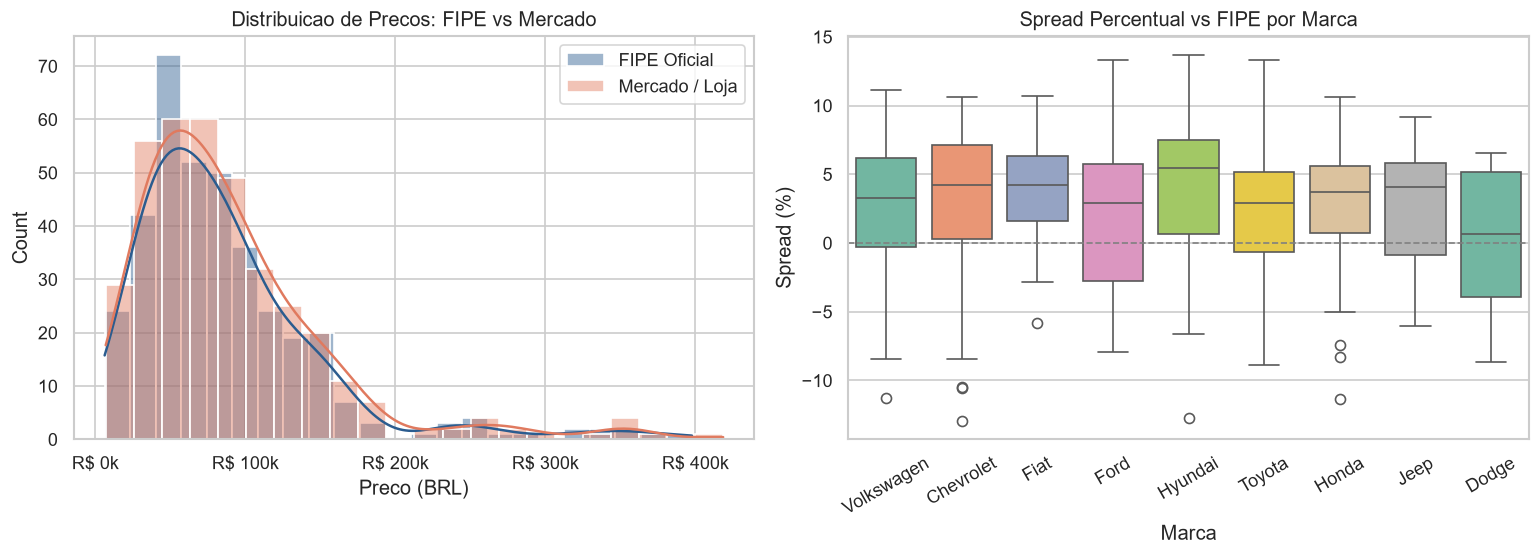

,brand,qtd,fipe_medio,mercado_medio,spread_medio_pct,score_medio
6,Jeep,21,142832.38,147214.29,2.69,87.67
4,Honda,46,120506.22,123691.30,2.92,88.11
7,Toyota,48,120488.06,122491.67,2.48,86.12
8,Volkswagen,48,88566.27,91668.75,2.81,87.62
1,Dodge,18,76861.56,77050.00,0.23,84.22
2,Fiat,38,67162.66,69789.47,3.85,87.47
5,Hyundai,45,66328.93,69726.67,4.08,86.69
0,Chevrolet,57,65306.46,66992.98,2.78,87.72
3,Ford,46,56076.22,57013.04,1.73,84.61


In [3]:
def fmt_brl(val, _pos):
    return f"R$ {val/1000:,.0f}k".replace(",", ".")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.histplot(df["fipe_price_brl"], kde=True, color="#2b5c8f", alpha=0.45, label="FIPE Oficial", ax=axes[0])
sns.histplot(df["market_asking_price"], kde=True, color="#e07a5f", alpha=0.45, label="Mercado / Loja", ax=axes[0])
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(fmt_brl))
axes[0].set_title("Distribuicao de Precos: FIPE vs Mercado")
axes[0].set_xlabel("Preco (BRL)")
axes[0].legend()

sns.boxplot(data=df, x="brand", y="fipe_spread_pct", hue="brand", legend=False, palette="Set2", ax=axes[1])
axes[1].axhline(0, color="gray", linestyle="--", linewidth=1)
axes[1].set_title("Spread Percentual vs FIPE por Marca")
axes[1].set_xlabel("Marca")
axes[1].set_ylabel("Spread (%)")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

brand_summary = (
    df.groupby("brand", as_index=False)
    .agg(
        qtd=("vehicle_id", "count"),
        fipe_medio=("fipe_price_brl", "mean"),
        mercado_medio=("market_asking_price", "mean"),
        spread_medio_pct=("fipe_spread_pct", "mean"),
        score_medio=("quality_score", "mean"),
    )
    .sort_values("fipe_medio", ascending=False)
)
display(brand_summary.round(2))

## 3. Estatística Inferencial: Correlações e Testes de Hipótese

Aplicamos testes estatísticos para responder a três perguntas práticas da mesa de avaliação da Ingá Multimarcas:
1. **Correlação:** Qual a força da associação linear (Pearson) e monotônica (Spearman) de `quality_score` e `km_per_year` com o spread vs FIPE?
2. **Praça Regional (Maringá/PR vs Outras Praças):** Existe diferença estatisticamente significativa no spread percentual em Maringá comparado às demais praças?
3. **Laudo Cautelar (Módulo 1 AutoMatch):** Veículos com laudo aprovado capturam prêmio de preço significativo frente aos veículos sem laudo?

quality_score   | Pearson r = +0.8334 (p=4.94e-96) | Spearman rho = +0.7691 (p=5.81e-73)
km_per_year     | Pearson r = -0.5611 (p=7.93e-32) | Spearman rho = -0.5451 (p=8.54e-30)
vehicle_age     | Pearson r = -0.0861 (p=9.95e-02) | Spearman rho = -0.0892 (p=8.78e-02)
fipe_price_brl  | Pearson r = -0.0017 (p=9.74e-01) | Spearman rho = +0.0658 (p=2.09e-01)

[Regiao] Maringa-PR (n=152, media=+3.63%) vs Outras (n=215, media=+2.16%): Welch t=2.820, p=5.0878e-03 | Mann-Whitney p=2.9417e-03
[Laudo]  Com Laudo (n=279, media=+4.62%) vs Sem Laudo (n=88, media=-3.09%): Welch t=16.068, p=4.8104e-33


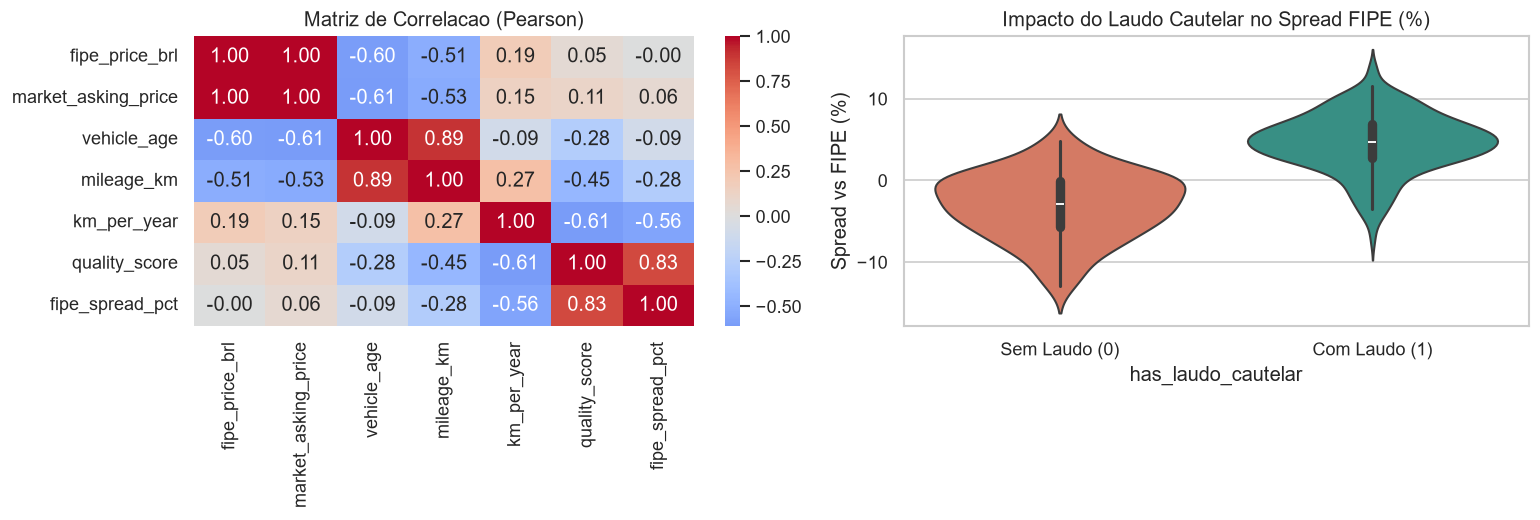

In [4]:
# 1) Correlacoes com Spread (%)
for col in ["quality_score", "km_per_year", "vehicle_age", "fipe_price_brl"]:
    r_p, p_p = stats.pearsonr(df[col], df["fipe_spread_pct"])
    r_s, p_s = stats.spearmanr(df[col], df["fipe_spread_pct"])
    print(f"{col:15s} | Pearson r = {r_p:+.4f} (p={p_p:.2e}) | Spearman rho = {r_s:+.4f} (p={p_s:.2e})")

# 2) Teste de hipotese: Maringa - PR vs Outras Pracas
maringa = df.loc[df["region_pr"] == "Maringa - PR", "fipe_spread_pct"]
outras = df.loc[df["region_pr"] != "Maringa - PR", "fipe_spread_pct"]
t_reg, p_reg = stats.ttest_ind(maringa, outras, equal_var=False)
u_reg, pu_reg = stats.mannwhitneyu(maringa, outras, alternative="two-sided")
print(
    f"\n[Regiao] Maringa-PR (n={len(maringa)}, media={maringa.mean():+.2f}%) vs Outras (n={len(outras)}, media={outras.mean():+.2f}%): "
    f"Welch t={t_reg:.3f}, p={p_reg:.4e} | Mann-Whitney p={pu_reg:.4e}"
)

# 3) Teste de hipotese: Com Laudo Cautelar vs Sem Laudo
com_laudo = df.loc[df["has_laudo_cautelar"] == 1, "fipe_spread_pct"]
sem_laudo = df.loc[df["has_laudo_cautelar"] == 0, "fipe_spread_pct"]
t_lau, p_lau = stats.ttest_ind(com_laudo, sem_laudo, equal_var=False)
print(
    f"[Laudo]  Com Laudo (n={len(com_laudo)}, media={com_laudo.mean():+.2f}%) vs Sem Laudo (n={len(sem_laudo)}, media={sem_laudo.mean():+.2f}%): "
    f"Welch t={t_lau:.3f}, p={p_lau:.4e}"
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(
    df[["fipe_price_brl", "market_asking_price", "vehicle_age", "mileage_km", "km_per_year", "quality_score", "fipe_spread_pct"]].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    ax=axes[0],
)
axes[0].set_title("Matriz de Correlacao (Pearson)")

sns.violinplot(
    data=df,
    x="has_laudo_cautelar",
    y="fipe_spread_pct",
    hue="has_laudo_cautelar",
    legend=False,
    palette=["#e76f51", "#2a9d8f"],
    ax=axes[1],
)
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Sem Laudo (0)", "Com Laudo (1)"])
axes[1].set_title("Impacto do Laudo Cautelar no Spread FIPE (%)")
axes[1].set_ylabel("Spread vs FIPE (%)")

plt.tight_layout()
plt.show()

## 4. Curva de Depreciação e Dinâmica por Segmento

Visualizamos o decaimento médio do valor FIPE conforme a idade do veículo por tipo de carroceria (`Hatch`, `Sedan`, `SUV`, `Pickup`, `Minivan`).

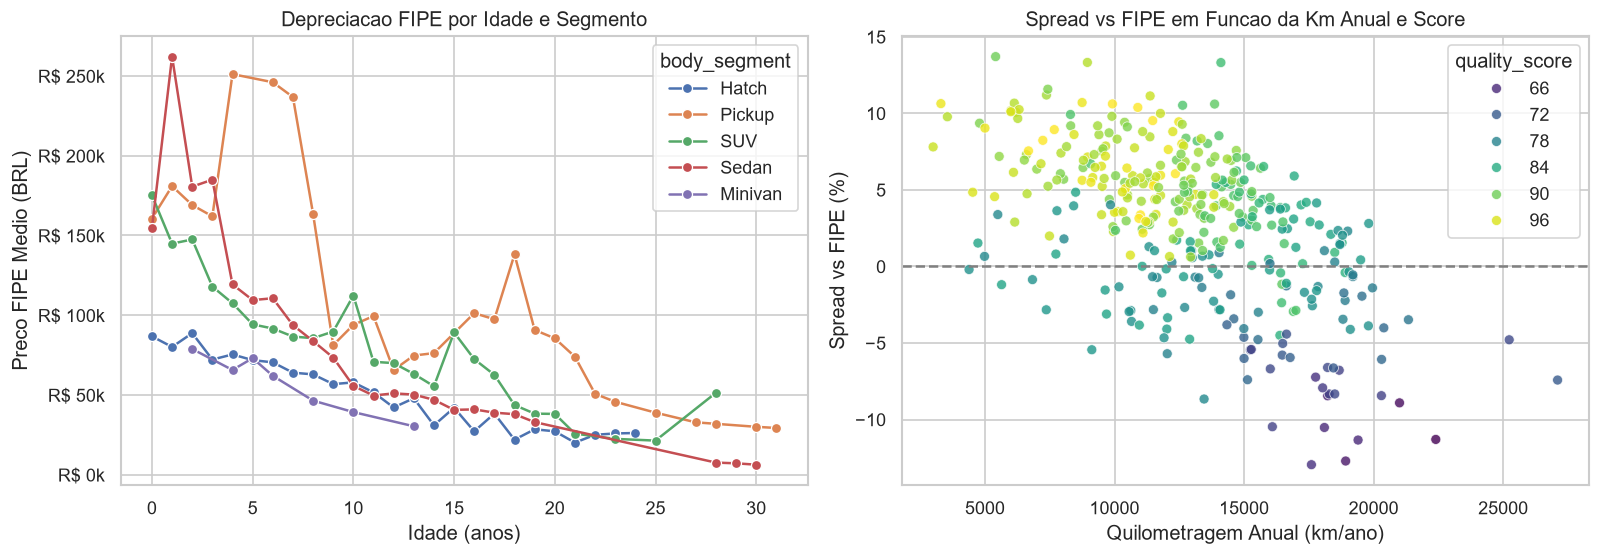

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
age_seg = df.groupby(["vehicle_age", "body_segment"], as_index=False)["fipe_price_brl"].mean()
sns.lineplot(data=age_seg, x="vehicle_age", y="fipe_price_brl", hue="body_segment", marker="o", ax=axes[0])
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(fmt_brl))
axes[0].set_title("Depreciacao FIPE por Idade e Segmento")
axes[0].set_xlabel("Idade (anos)")
axes[0].set_ylabel("Preco FIPE Medio (BRL)")

sns.scatterplot(
    data=df,
    x="km_per_year",
    y="fipe_spread_pct",
    hue="quality_score",
    palette="viridis",
    alpha=0.8,
    ax=axes[1],
)
axes[1].axhline(0, color="gray", linestyle="--")
axes[1].set_title("Spread vs FIPE em Funcao da Km Anual e Score")
axes[1].set_xlabel("Quilometragem Anual (km/ano)")
axes[1].set_ylabel("Spread vs FIPE (%)")

plt.tight_layout()
plt.show()

## 5. Pipeline de Machine Learning e Validação Cruzada (Scikit-learn)

Construímos um `Pipeline` reprodutível com `ColumnTransformer` (`SimpleImputer` + `StandardScaler` para variáveis numéricas e `OneHotEncoder` para categóricas) e comparamos quatro estimadores usando **5-Fold Cross-Validation** e avaliação em conjunto **Holdout (20%) estratificado por quintis de preço**.

In [6]:
numeric_features = [
    "fipe_price_brl",
    "model_year",
    "vehicle_age",
    "mileage_km",
    "km_per_year",
    "quality_score",
    "engine_liters",
    "has_laudo_cautelar",
]
categorical_features = [
    "brand",
    "body_segment",
    "fuel_type",
    "transmission",
    "region_pr",
    "liquidity_tier",
]
feature_cols = numeric_features + categorical_features
target_col = "market_asking_price"

X = df[feature_cols].copy()
y = df[target_col].copy()
price_bins = pd.qcut(y, q=5, labels=False, duplicates="drop")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=price_bins
)

def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            (
                "num",
                Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]),
                numeric_features,
            ),
            (
                "cat",
                Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]),
                categorical_features,
            ),
        ]
    )

candidates = {
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(alpha=5.0),
    "RandomForestRegressor": RandomForestRegressor(n_estimators=300, max_depth=14, min_samples_leaf=2, random_state=42, n_jobs=-1),
    "GradientBoostingRegressor": GradientBoostingRegressor(n_estimators=260, learning_rate=0.05, max_depth=4, subsample=0.85, random_state=42),
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
    "r2": "r2",
    "mape": "neg_mean_absolute_percentage_error",
}

rows = []
trained = {}
for name, est in candidates.items():
    pipe = Pipeline([("preprocessor", make_preprocessor()), ("regressor", est)])
    cv_res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    rows.append({
        "Modelo": name,
        "CV_RMSE_BRL": round(-cv_res["test_rmse"].mean(), 2),
        "CV_R2": round(cv_res["test_r2"].mean(), 5),
        "Test_RMSE_BRL": round(root_mean_squared_error(y_test, preds), 2),
        "Test_MAE_BRL": round(mean_absolute_error(y_test, preds), 2),
        "Test_R2": round(r2_score(y_test, preds), 5),
        "Test_MAPE_pct": round(mean_absolute_percentage_error(y_test, preds) * 100.0, 3),
    })
    trained[name] = pipe

results_df = pd.DataFrame(rows).sort_values("Test_RMSE_BRL").reset_index(drop=True)
display(results_df)

best_name = results_df.loc[0, "Modelo"]
best_pipe = trained[best_name]
y_pred = best_pipe.predict(X_test)
print(f"Modelo vencedor no holdout: {best_name}")

,Modelo,CV_RMSE_BRL,CV_R2,Test_RMSE_BRL,Test_MAE_BRL,Test_R2,Test_MAPE_pct
0,GradientBoostingRegressor,6559.44,0.98893,3693.81,2423.96,0.99637,2.725
1,RandomForestRegressor,8203.50,0.98290,4925.53,3072.71,0.99355,3.521
2,Ridge,4311.51,0.99470,4967.12,2647.43,0.99344,3.891
3,LinearRegression,3538.65,0.99657,5934.62,2556.65,0.99063,3.293


Modelo vencedor no holdout: GradientBoostingRegressor


## 6. Diagnóstico de Resíduos, Importância das Features e Recomendações de Negócio

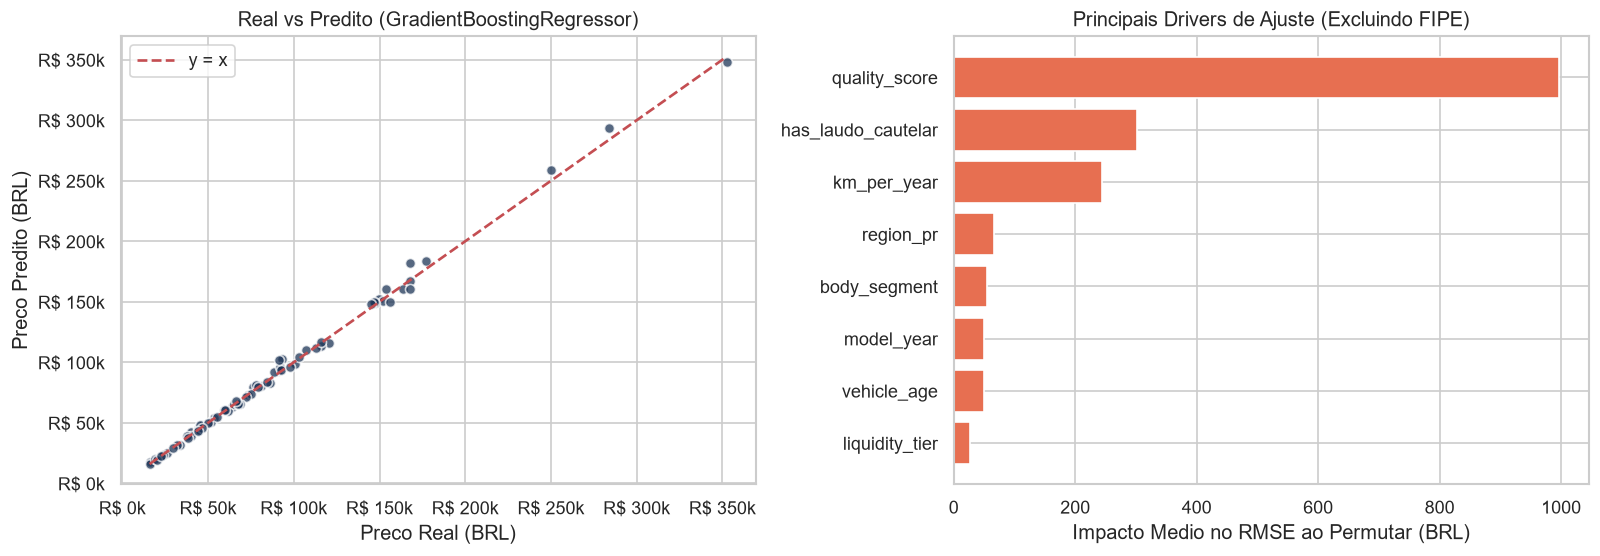

,feature,importance_rmse_brl
0,fipe_price_brl,84741.43
5,quality_score,995.72
7,has_laudo_cautelar,302.47
4,km_per_year,244.43
12,region_pr,66.45
9,body_segment,54.77
1,model_year,49.50
2,vehicle_age,49.23
13,liquidity_tier,26.13
6,engine_liters,9.06


In [7]:
residuals = y_test.to_numpy() - y_pred
perm = permutation_importance(
    best_pipe, X_test, y_test, n_repeats=15, random_state=42, scoring="neg_root_mean_squared_error"
)
imp_df = pd.DataFrame({
    "feature": feature_cols,
    "importance_rmse_brl": perm.importances_mean,
}).sort_values("importance_rmse_brl", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
axes[0].scatter(y_test, y_pred, alpha=0.75, color="#1d3557", edgecolors="white")
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].plot(lims, lims, "r--", linewidth=1.6, label="y = x")
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(fmt_brl))
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(fmt_brl))
axes[0].set_title(f"Real vs Predito ({best_name})")
axes[0].set_xlabel("Preco Real (BRL)")
axes[0].set_ylabel("Preco Predito (BRL)")
axes[0].legend()

non_fipe = imp_df[imp_df["feature"] != "fipe_price_brl"].head(8).sort_values("importance_rmse_brl")
axes[1].barh(non_fipe["feature"], non_fipe["importance_rmse_brl"], color="#e76f51")
axes[1].set_title("Principais Drivers de Ajuste (Excluindo FIPE)")
axes[1].set_xlabel("Impacto Medio no RMSE ao Permutar (BRL)")

plt.tight_layout()
plt.show()

display(imp_df.round(2))

### Conclusões Executivas para a Operação AutoMatch (Ingá Multimarcas)
- **Âncora FIPE + Ajustes Não-Lineares:** Embora o valor FIPE seja o principal determinante do patamar de preço, variáveis operacionais (`quality_score`, `km_per_year`, `has_laudo_cautelar`, `vehicle_age` e `region_pr`) explicam os desvios de precificação entre veículos equivalentes na loja.
- **Valor do Laudo Cautelar:** Veículos com laudo cautelar validado sustentam spread positivo frente à referência FIPE, reforçando o ROI do Módulo 1 (auditoria PDF) no fluxo do AutoMatch.
- **Gestão Regional (Maringá/PR):** A praça de Maringá apresenta maior liquidez e sustentação de preço em seminovos de baixo desgaste, permitindo calibrar automaticamente a *torna* sugerida nas propostas de permuta.